In [164]:
import os
from pathlib import Path

import numpy as np

import io
import pandas as pd

import lasair
import requests
import hashlib

from collections import defaultdict
from scipy.stats import binned_statistic

from matplotlib.patches import Wedge

import matplotlib.pyplot as plt
from matplotlib import cm, colors
plt.style.use("/Users/leo/Projects/LBG_cosmology/code/umap_nz_cal.mplstyle")

# 1: Select Lasair objects w/redshifts

In [4]:
### Set up Lasair access

def get_token():
    """Token from $LASAIR_TOKEN, else ~/.lasair_token."""
    token = os.environ.get("LASAIR_TOKEN")
    if token:
        return token.strip()
    path = Path.home() / ".lasair_token"
    if path.exists():
        return path.read_text().strip()
    raise RuntimeError(
        "No Lasair token found. Put it in ~/.lasair_token or set $LASAIR_TOKEN "
        "(https://lasair.lsst.ac.uk -> your name -> My Profile)."
    )


# Responses are cached on disk, so re-running a cell doesn't spend quota.
CACHE = Path("lasair_cache")
CACHE.mkdir(exist_ok=True)

# Default endpoint is the LSST instance, https://api.lasair.lsst.ac.uk/api .
# For ZTF, pass endpoint="https://api.lasair-ztf.lsst.ac.uk/api".
L = lasair.lasair_client(get_token(), cache=str(CACHE), timeout=300)

L.query(selected="diaObjectId", tables="objects", conditions="", limit=1)  # smoke test

[{'diaObjectId': 170657504701711053}]

In [5]:
OBJECT_COLUMNS = [
    "objects.diaObjectId",
    "objects.ra",
    "objects.decl",
    "objects.firstDiaSourceMjdTai",
    "objects.lastDiaSourceMjdTai",
    "objects.nDiaSources",
    "objects.latest_psfFlux",
    "objects.absMag",  # only set where Sherlock has a distance: ~98% null
]
SHERLOCK_COLUMNS = ["sherlock_classifications.classification"]

MAX_PAGE = 10_000  # server-side cap on rows per call

CONDITIONS_MAX = 4096   # Lasair's limit on the `conditions` field

OBJECT_FIELDS = ("objects.diaObjectId, objects.ra, objects.decl, objects.nDiaSources, "
                 "objects.firstDiaSourceMjdTai, objects.lastDiaSourceMjdTai, objects.latest_psfFlux")

SHERLOCK_FIELDS = ("sherlock_classifications.classification, sherlock_classifications.raDeg, "
                   "sherlock_classifications.decDeg, sherlock_classifications.separationArcsec, "
                   "sherlock_classifications.physical_separation_kpc, sherlock_classifications.z, "
                   "sherlock_classifications.photoZ, sherlock_classifications.catalogue_table_name")

MODES = {
    # mode: (selected, tables) -- the server adds the join condition for the second table
    "hosts":   (OBJECT_FIELDS + ", " + SHERLOCK_FIELDS, "objects, sherlock_classifications"),
    "objects": (OBJECT_FIELDS, "objects"),
}

# Server-side cut: any object whose Sherlock match has a spec-z or a photo-z, whatever its class.
# The redshift belongs to Sherlock's matched source, so what it means depends on `classification`:
#   SN, NT   -> the host galaxy (offset from it / on its nucleus)
#   AGN      -> the AGN or quasar itself
#   UNCLEAR  -> an ambiguous match; VS/CV -> a handful of stray matches
HAS_Z = ("(sherlock_classifications.z IS NOT NULL "
         "OR sherlock_classifications.photoZ IS NOT NULL)")
# The earlier, narrower selection (host redshifts only), kept for reference:
HOST_Z_TRANSIENTS = HAS_Z# + " AND sherlock_classifications.classification IN ('SN','NT')"

In [ ]:
def objects_with_z(max_rows         = 200_000,
                   extra_conditions = None, 
                   cuts             = HAS_Z,
                   page_size        = MAX_PAGE,
                   verbose          = True):
    
    """Every Lasair object passing `cuts`, up to `max_rows`.

    extra_conditions: more SQL ANDed on, e.g. "objects.nDiaSources > 10".
    Costs ceil(min(max_rows, total) / page_size) calls; count it first with
    L.query(selected="count(*) AS n", tables="objects, sherlock_classifications", ...).
    """
    
    selected, tables = MODES["hosts"]
    conditions = cuts + (f" AND ({extra_conditions})" if extra_conditions else "")

    rows, last_id = [], None
    while len(rows) < max_rows:
        page_conditions = conditions
        if last_id is not None:
            page_conditions += f" AND objects.diaObjectId > {last_id}"
        page_conditions += " ORDER BY objects.diaObjectId"
        limit = min(page_size, MAX_PAGE, max_rows - len(rows))

        page = L.query(selected=selected, tables=tables, conditions=page_conditions, limit=limit)
        if isinstance(page, dict) and "error" in page:
            raise RuntimeError(page["error"])
        rows.extend(page)
        if verbose:
            print(f"call: +{len(page)} rows (total {len(rows)})")
        if len(page) < limit:
            break
        last_id = page[-1]["diaObjectId"]

    df = pd.DataFrame(rows)
    if not df.empty:
        df["z_is_spec"] = df.z.notna()
        df["z_best"] = df.z.fillna(df.photoZ)
    return df


N_MAX = 200_000

all_hosted = objects_with_z(max_rows=N_MAX)
# all_hosted["in_alerce"] = all_hosted.diaObjectId.isin(oids)
all_hosted.to_csv("lasair_objects_with_z.csv", index=False)

print(f"\n{len(all_hosted)} objects with a redshift")
print(all_hosted.classification.value_counts().to_string())
print(f"spec-z: {all_hosted.z_is_spec.sum()}, photo-z only: {(~all_hosted.z_is_spec).sum()}")
# print(f"also in the ALeRCE list: {all_hosted.in_alerce.sum()}")
all_hosted.head()

call: +10000 rows (total 10000)
call: +10000 rows (total 20000)
call: +10000 rows (total 30000)
call: +10000 rows (total 40000)
call: +10000 rows (total 50000)
call: +10000 rows (total 60000)
call: +10000 rows (total 70000)
call: +10000 rows (total 80000)
call: +10000 rows (total 90000)
call: +7929 rows (total 97929)

97929 objects with a redshift
SN         74017
AGN        13930
NT          9660
UNCLEAR      316
VS             5
CV             1
spec-z: 54685, photo-z only: 43244


,diaObjectId,ra,decl,nDiaSources,firstDiaSourceMjdTai,lastDiaSourceMjdTai,latest_psfFlux,classification,raDeg,decDeg,separationArcsec,physical_separation_kpc,z,photoZ,catalogue_table_name,z_is_spec,z_best
0,170019695466905747,54.069402,-28.986703,3,61088.093945,61355.236050,1694.960,AGN,54.069424,-28.986747,0.175,1.481,1.789000,NaN,MILLIQUAS/GAIA/PS1,True,1.789000
1,170019695496790075,53.024724,-28.329677,12,61088.093945,61358.267723,1352.510,SN,53.012670,-28.358580,110.866,10.361,0.004526,NaN,LASR,True,0.004526
2,170019695515664405,53.691223,-27.566856,3,61088.093945,61358.267723,763.856,AGN,53.691130,-27.566833,0.328,2.644,1.033000,NaN,MILLIQUAS,True,1.033000
3,170019695632056359,52.598308,-28.425292,13,61088.094344,61358.273145,2371.360,AGN,52.598309,-28.425292,0.355,2.433,0.635000,NaN,MILLIQUAS/GAIA/PS1,True,0.635000
4,170019695640445032,51.575537,-28.499729,10,61088.094344,61358.273145,-4896.130,AGN,51.575529,-28.499699,0.102,0.783,0.860000,NaN,MILLIQUAS/GAIA,True,0.860000


# 2: Pull those same transients from ALeRCE

In [7]:
TAP_URL = "https://tap.alerce.online/tap"
LSST_SID = 1   # ALeRCE's survey id for LSST. ZTF rows live in the same tables, so always filter on it.

In [ ]:
def tap_query(adql, maxrec=100_000, timeout=600, warn=True):
    
    """Run an ADQL query against ALeRCE TAP and return a DataFrame. """
    
    r = requests.post(
        f"{TAP_URL}/sync",
        data={"LANG": "ADQL", "REQUEST": "doQuery", "RESPONSEFORMAT": "csv",
              "MAXREC": maxrec, "QUERY": adql},
        timeout=timeout,
    )
    
    r.raise_for_status()
    
    df = pd.read_csv(io.BytesIO(r.content))
    if warn and len(df) == maxrec:
        print(f"Warning: got exactly MAXREC={maxrec} rows — the result is probably truncated.")
    return df


tap_query("SELECT TOP 3 oid, ra, dec, ndiasources FROM alerce_tap.lsst_dia_object", maxrec=10)

,oid,ra,dec,ndiasources
0,170019695986999725,53.882887,-29.655230,1
1,170019695986999803,53.968238,-29.537739,1
2,170019695987523606,53.614588,-29.765139,1


In [ ]:
tap_query("""
    SELECT table_name, description
    FROM tap_schema.tables
    WHERE schema_name = 'alerce_tap' AND table_name LIKE '%lsst%'
""", maxrec=100)

,table_name,description
0,alerce_tap.lsst_dia_object,\nSummary catalog of transient and variable ob...
1,alerce_tap.lsst_ss_object,\nProperties of solar system objects observed ...
2,alerce_tap.lsst_mpc_orbits,\nComplete orbital solutions from the Minor Pl...
3,alerce_tap.lsst_detection,\nIndividual LSST Difference Image Analysis so...
4,alerce_tap.lsst_ss_detection,\nIndividual LSST detections associated with s...
5,alerce_tap.lsst_forced_photometry,\nLSST forced photometry measurements extracte...


In [10]:
ALERCE_CACHE = Path("alerce_cache")
ALERCE_CACHE.mkdir(exist_ok=True)


def alerce_probabilities(oids, batch_size=5000, verbose=True):
    """Every ALeRCE LSST probability row for `oids`: all classifiers, all classes."""
    oids = np.unique(np.asarray(oids, dtype="int64"))
    batches = [oids[i:i + batch_size] for i in range(0, len(oids), batch_size)]

    frames = []
    for i, batch in enumerate(batches):
        id_list = ",".join(map(str, batch))
        cached = ALERCE_CACHE / f"probs_{hashlib.sha1(id_list.encode()).hexdigest()[:16]}.csv"
        from_cache = cached.exists()
        if from_cache:
            chunk = pd.read_csv(cached)
        else:
            chunk = tap_query(f"""
                SELECT oid, classifier_id, classifier_version, class_id, probability, ranking
                FROM alerce_tap.probability
                WHERE sid = {LSST_SID} AND oid IN ({id_list})
            """, maxrec=1_000_000)
            chunk.to_csv(cached, index=False)
        frames.append(chunk)
        if verbose:
            print(f"batch {i + 1}/{len(batches)}: {len(chunk):,} rows"
                  + (" (cached)" if from_cache else ""))
    return pd.concat(frames, ignore_index=True)


probs = alerce_probabilities(all_hosted.diaObjectId)
print(f"\n{len(probs):,} probability rows for {probs.oid.nunique():,} of "
      f"{all_hosted.diaObjectId.nunique():,} Lasair objects")
probs.groupby(["classifier_id", "classifier_version"]).size()

batch 1/20: 49,970 rows (cached)
batch 2/20: 50,000 rows (cached)
batch 3/20: 50,000 rows (cached)
batch 4/20: 50,000 rows (cached)
batch 5/20: 50,000 rows (cached)
batch 6/20: 49,995 rows (cached)
batch 7/20: 50,000 rows (cached)
batch 8/20: 50,000 rows (cached)
batch 9/20: 50,000 rows (cached)
batch 10/20: 50,000 rows (cached)
batch 11/20: 50,014 rows (cached)
batch 12/20: 50,226 rows (cached)
batch 13/20: 50,466 rows (cached)
batch 14/20: 47,658 rows (cached)
batch 15/20: 26,314 rows (cached)
batch 16/20: 47,822 rows (cached)
batch 17/20: 50,000 rows (cached)
batch 18/20: 50,002 rows (cached)
batch 19/20: 50,000 rows (cached)
batch 20/20: 29,290 rows (cached)

951,757 probability rows for 97,929 of 97,929 Lasair objects


classifier_id  classifier_version
1              201                   459410
3              202                   489645
10             1                       2702
dtype: int64

In [11]:
taxonomy = tap_query("SELECT class_id, class_name, taxonomy_order, classifier_id "
                     "FROM alerce_tap.taxonomy", maxrec=1000)


def collate_probabilities(probs, taxonomy):
    """Name each probability row, keep the latest classifier version, and build
    (dicts, wide): dicts maps oid -> {classifier_id: {class_name: p}}, wide is an
    oid-indexed DataFrame with one clf<id>_<class> column per (classifier, class)."""
    named = probs.merge(taxonomy[["classifier_id", "class_id", "class_name", "taxonomy_order"]],
                        on=["classifier_id", "class_id"], how="left")
    unnamed = named.class_name.isna()
    if unnamed.any():
        print(f"note: {unnamed.sum():,} rows have a (classifier, class) pair missing from the "
              "taxonomy; named class<id>")
        named.loc[unnamed, "class_name"] = "class" + named.loc[unnamed, "class_id"].astype(str)

    named = (named.sort_values("classifier_version", kind="stable")
                  .drop_duplicates(["oid", "classifier_id", "class_id"], keep="last")
                  .sort_values(["oid", "classifier_id", "taxonomy_order", "class_id"]))

    dicts = defaultdict(dict)
    for oid, clf, name, p in zip(named.oid, named.classifier_id, named.class_name,
                                 named.probability):
        dicts[int(oid)].setdefault(int(clf), {})[name] = float(p)

    named["column"] = "clf" + named.classifier_id.astype(str) + "_" + named.class_name
    column_order = named.drop_duplicates("column").sort_values(
        ["classifier_id", "taxonomy_order", "class_id"]).column
    wide = named.pivot(index="oid", columns="column", values="probability")[list(column_order)]
    wide.columns.name = None
    return dicts, wide


prob_dicts, wide = collate_probabilities(probs, taxonomy)

# Re-running this cell replaces, rather than duplicates, the probability columns.
all_hosted = all_hosted.drop(columns=[c for c in all_hosted.columns
                                      if c == "probabilities" or c.startswith("clf")])
all_hosted["probabilities"] = [prob_dicts.get(int(i), {}) for i in all_hosted.diaObjectId]
all_hosted = all_hosted.merge(wide, left_on="diaObjectId", right_index=True, how="left")

scored = all_hosted.probabilities.map(bool)
print(f"{scored.sum():,} of {len(all_hosted):,} objects have ALeRCE probabilities")
print("columns:", list(wide.columns))
all_hosted.loc[scored, ["diaObjectId", "classification", "z_best", "probabilities"]].head()

97,929 of 97,929 objects have ALeRCE probabilities
columns: ['clf1_SN', 'clf1_AGN', 'clf1_VS', 'clf1_asteroid', 'clf1_bogus', 'clf3_SN', 'clf3_AGN', 'clf3_VS', 'clf3_asteroid', 'clf3_bogus', 'clf10_SNoffnuclear', 'clf10_notSNoffnuclear']


,diaObjectId,classification,z_best,probabilities
0,170019695466905747,AGN,1.789000,"{3: {'SN': 0.0076868306, 'AGN': 0.20051135, 'V..."
1,170019695496790075,SN,0.004526,"{3: {'SN': 0.0024161139, 'AGN': 0.9559722, 'VS..."
2,170019695515664405,AGN,1.033000,"{3: {'SN': 0.01467924, 'AGN': 0.18730639, 'VS'..."
3,170019695632056359,AGN,0.635000,"{3: {'SN': 0.0055033555, 'AGN': 0.83559114, 'V..."
4,170019695640445032,AGN,0.860000,"{3: {'SN': 0.0060608923, 'AGN': 0.9519649, 'VS..."


# 3: Understand what's inside the table

Text(0.16, 1.0, 'All Lasair objects')

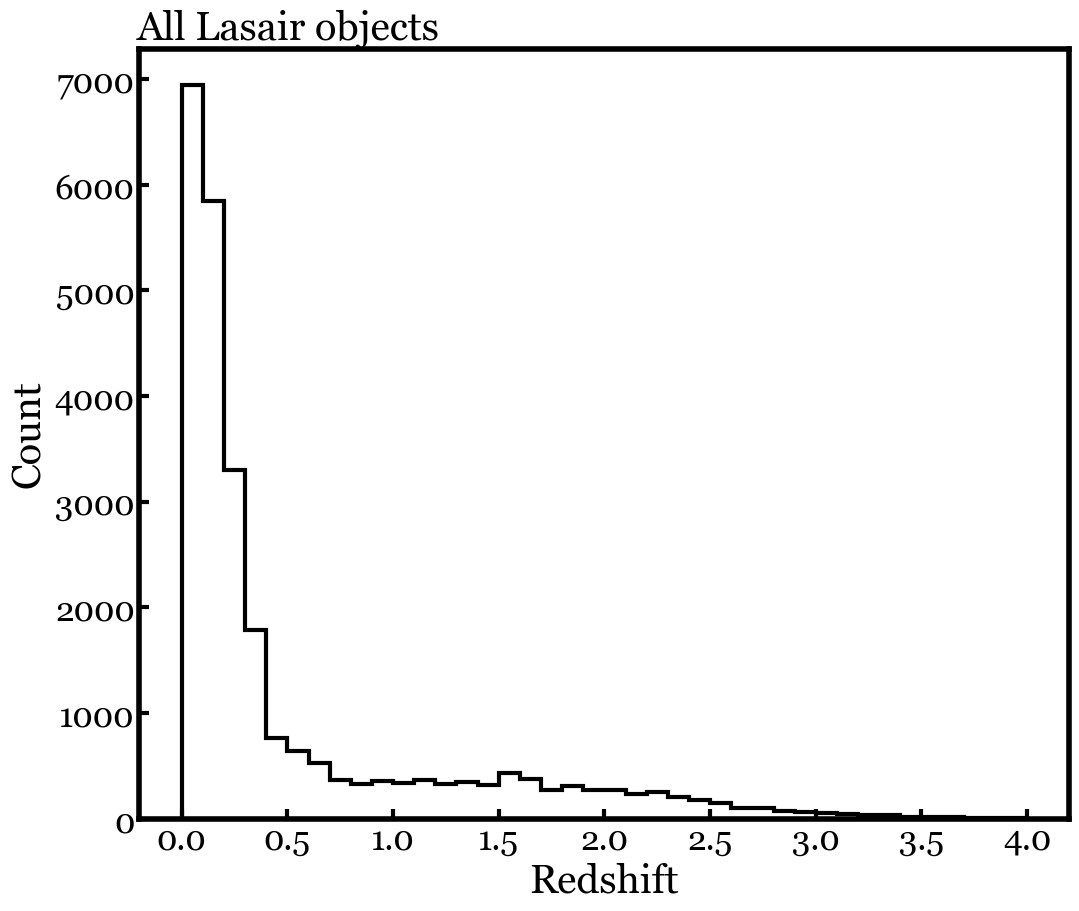

In [233]:
fig, ax = plt.subplots()

bool_good = all_hosted["nDiaSources"] > 5

bins = np.arange(0, 4.1, 0.1)
ax.hist(all_hosted[bool_good]["z_best"], bins = bins, histtype = "step", color = "black", linewidth = 3)

ax.set(ylabel = "Count", xlabel = "Redshift")
ax.set_title("All Lasair objects", x = 0.16)

Text(0.5, 1.0, 'All Lasair objects (nDiaSources > 5). Total = 26,174')

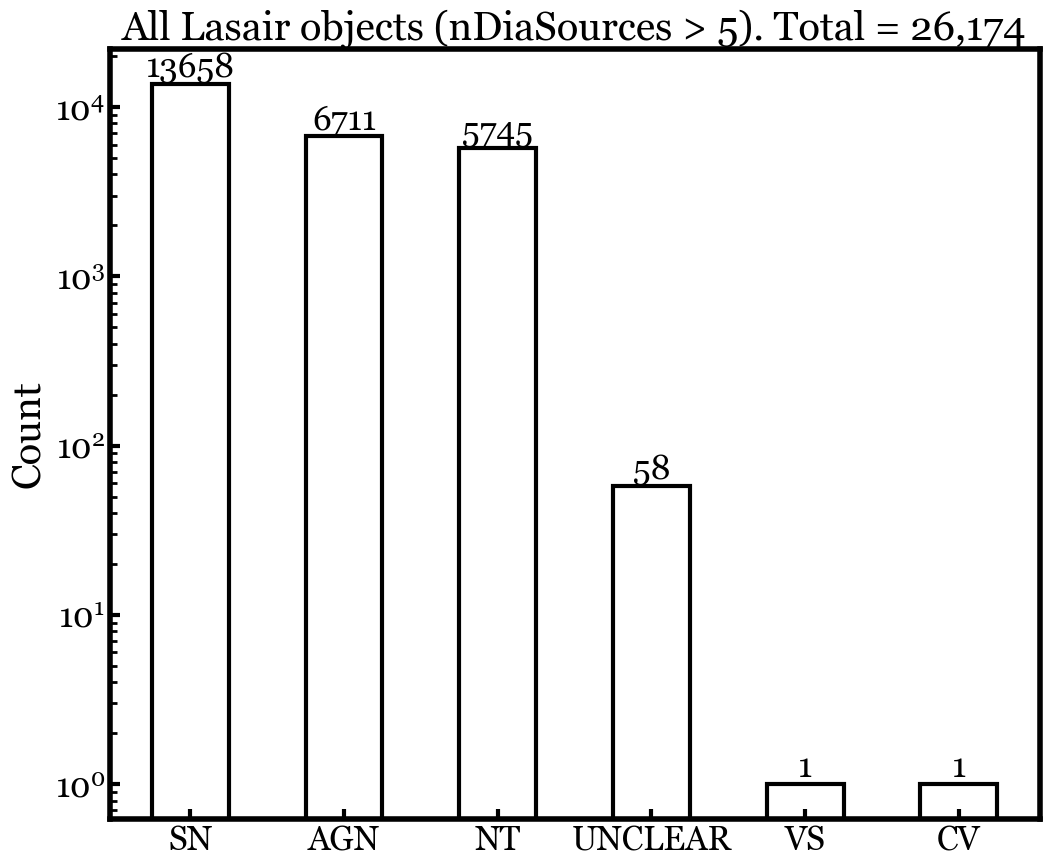

In [280]:
fig, ax = plt.subplots()

bool_good = all_hosted["nDiaSources"] > 5

types      = np.unique(all_hosted[bool_good]["classification"])
barHeights = np.array([sum(all_hosted[bool_good]["classification"] == type) for type in types])

sortedIdx = np.argsort(barHeights)[::-1]

ax.bar(types[sortedIdx], barHeights[sortedIdx],
       width = 0.5, edgecolor = "black", facecolor = "none", linewidth = 3)
for i in range(len(types)):
    ax.text(types[sortedIdx][i], barHeights[sortedIdx][i] * 1.1, barHeights[sortedIdx][i],
            horizontalalignment = "center")

ax.set(ylabel = "Count", yscale = "log")
ax.set_title(f"All Lasair objects (nDiaSources > 5). Total = {bool_good.sum():,}")

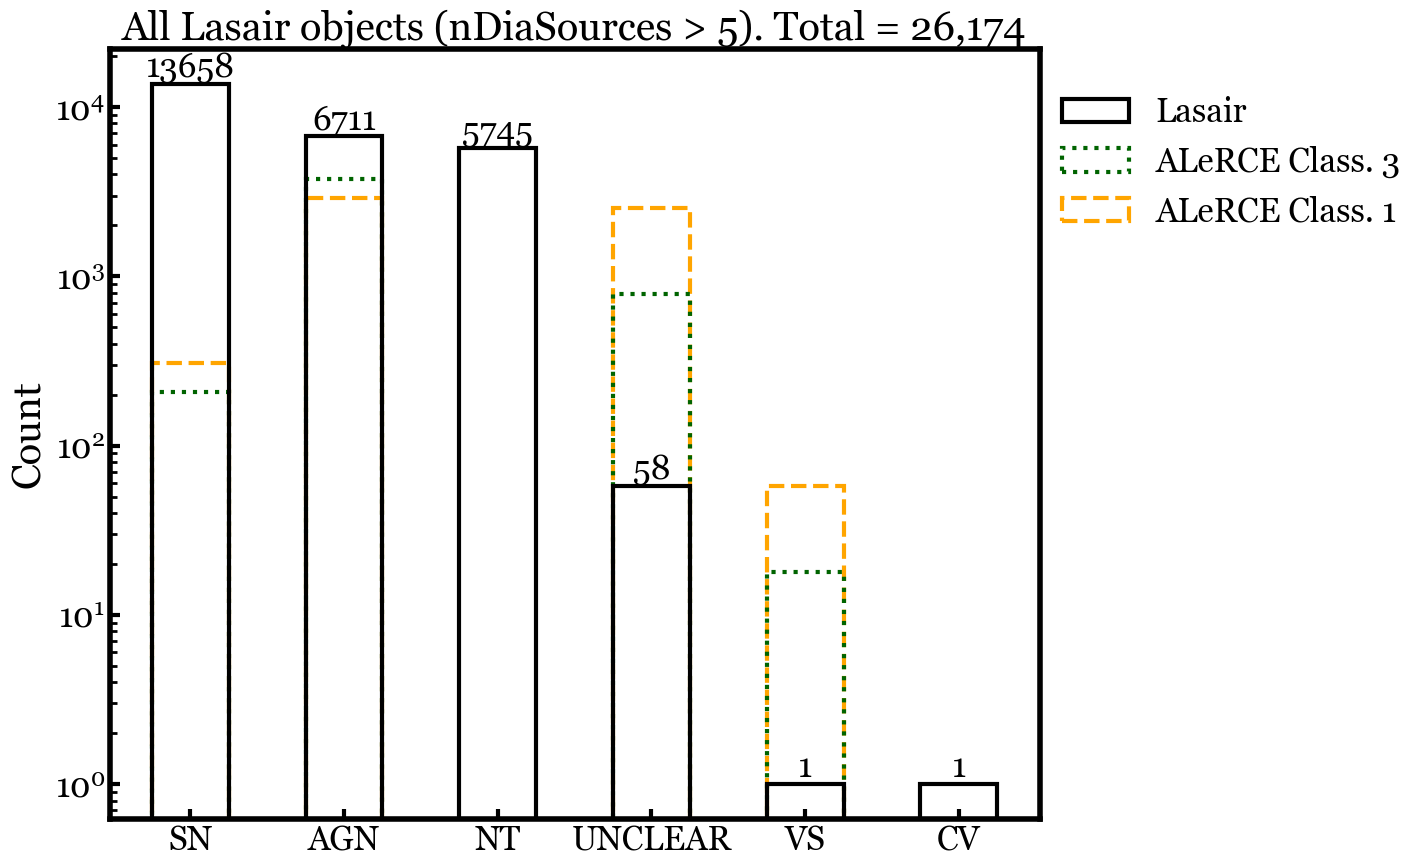

In [316]:
fig, ax = plt.subplots()

bool_good = all_hosted["nDiaSources"] > 5

types      = np.array(np.unique(all_hosted[bool_good]["classification"]), dtype = str)
barHeights = np.array([sum(all_hosted[bool_good]["classification"] == type) for type in types])

barHeights_ALclf1 = np.zeros_like(barHeights)

sortedIdx = np.argsort(barHeights)[::-1]

ax.bar(types[sortedIdx], barHeights[sortedIdx],
       width = 0.5, edgecolor = "black", facecolor = "none", linewidth = 3, label = "Lasair", zorder = 3)


barHeights_ALclf1 = np.array([sum(all_hosted[bool_good][f"clf1_{type}"] > 0.9) if type else 0 for type in ["SN", "AGN", None, "bogus", "VS", None]])
barHeights_ALclf3 = np.array([sum(all_hosted[bool_good][f"clf3_{type}"] > 0.9) if type else 0 for type in ["SN", "AGN", None, "bogus", "VS", None]])
ax.bar(types[sortedIdx], barHeights_ALclf3,
       width = 0.5, edgecolor = "darkgreen", facecolor = "none", linewidth = 3, linestyle = ":", label = "ALeRCE Class. 3", zorder = 2)
ax.bar(types[sortedIdx], barHeights_ALclf1,
       width = 0.5, edgecolor = "orange", facecolor = "none", linewidth = 3, linestyle = "--", label = "ALeRCE Class. 1", zorder = 1)

for i in range(len(types)):
    ax.text(types[sortedIdx][i], barHeights[sortedIdx][i] * 1.1, barHeights[sortedIdx][i],
            horizontalalignment = "center")

ax.set(ylabel = "Count", yscale = "log")
ax.set_title(f"All Lasair objects (nDiaSources > 5). Total = {bool_good.sum():,}")

ax.legend(frameon = False, loc = (1.01, 0.75))

# 4: Compare classifications

In [ ]:
### Lasair has the following classifications:
np.unique(all_hosted["classification"])

array(['AGN', 'CV', 'NT', 'SN', 'UNCLEAR', 'VS'], dtype=object)

In [318]:
def histColoredByValue(x, z, bins = 30, cmap = "cool", statistic = "median", ax = None, label = None,
                        vmin = None, vmax = None, noValueColor = "lightgrey", showbar = True):
    
    counts, edges = np.histogram(x, bins = bins)
    stat, _, _ = binned_statistic(x, z, statistic = statistic, bins = edges)
    
    norm = colors.Normalize(vmin = vmin if vmin != None else np.nanmin(stat), vmax = vmax if vmax != None else np.nanmax(stat))
    cmap = plt.get_cmap(cmap)
    bar_colors = [cmap(norm(m)) if np.isfinite(m) else noValueColor for m in stat]
        
    ax = ax or plt.gca()
    
    ax.bar(edges[:-1], counts, width = np.diff(edges), align = "edge", color = bar_colors, edgecolor = "none")
    if showbar:
        ax.figure.colorbar(cm.ScalarMappable(norm = norm, cmap = cmap), ax = ax, label = label)

[(0.0, 1300.0),
 Text(0.5, 0, 'Probability that ALeRCE\nclassifier 3 agrees with Lasair'),
 Text(0, 0.5, 'Count'),
 Text(0.5, 1.0, 'AGN')]

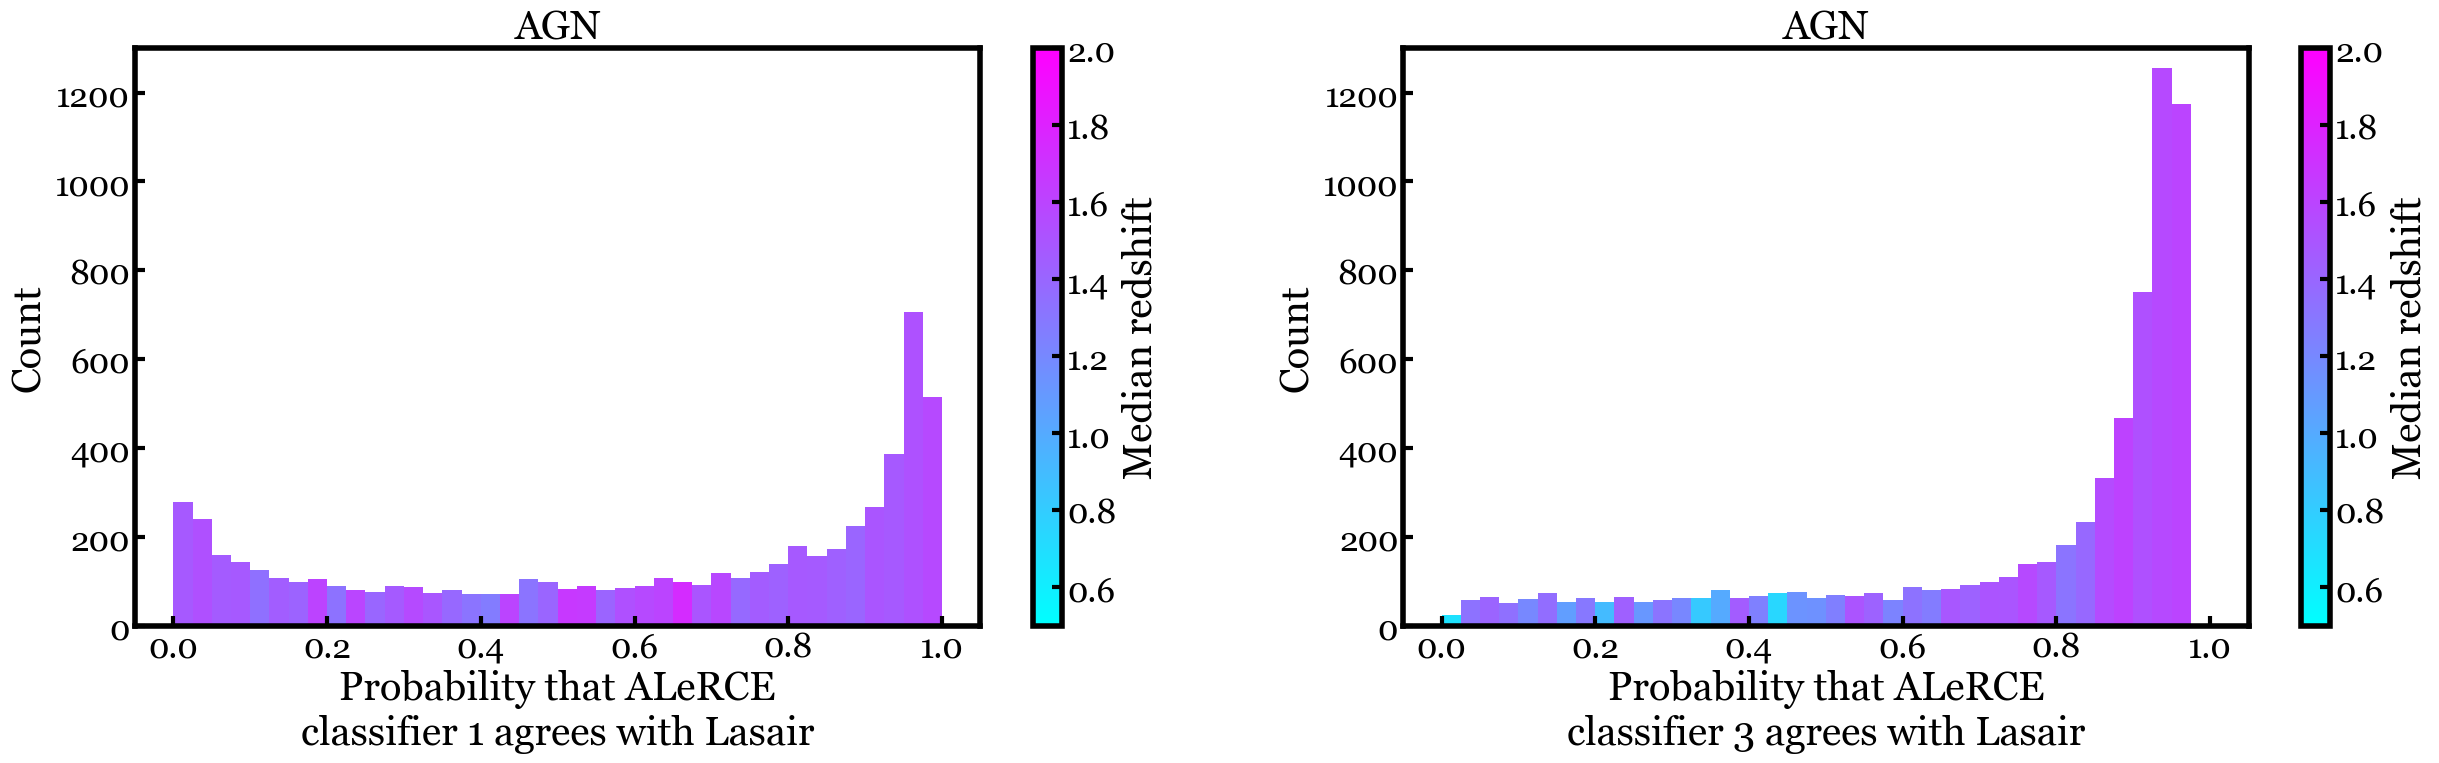

In [322]:
fig, axs = plt.subplots(1, 2, figsize = (30, 7.5))

bool_lasair_agn = (all_hosted["classification"] == "AGN") & (all_hosted["nDiaSources"] > 5) & (all_hosted["z_best"] > 0)
bins = np.arange(0, 1.01, 0.025)

histColoredByValue(all_hosted[bool_lasair_agn]["clf1_AGN"], all_hosted[bool_lasair_agn]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[0], cmap = "cool", vmin = 0.5, vmax = 2)

histColoredByValue(all_hosted[bool_lasair_agn]["clf3_AGN"], all_hosted[bool_lasair_agn]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[1], cmap = "cool", vmin = 0.5, vmax = 2)

axs[0].set(ylim = (0, 1300),
            xlabel = "Probability that ALeRCE\nclassifier 1 agrees with Lasair", ylabel = "Count",
            title = "AGN")
axs[1].set(ylim = (0, 1300),
            xlabel = "Probability that ALeRCE\nclassifier 3 agrees with Lasair", ylabel = "Count",
            title = "AGN")

[None,
 Text(0.5, 0, 'Probability that ALeRCE classifier 3\nagrees with Lasair'),
 Text(0, 0.5, 'Count'),
 Text(0.5, 1.0, 'Supernova')]

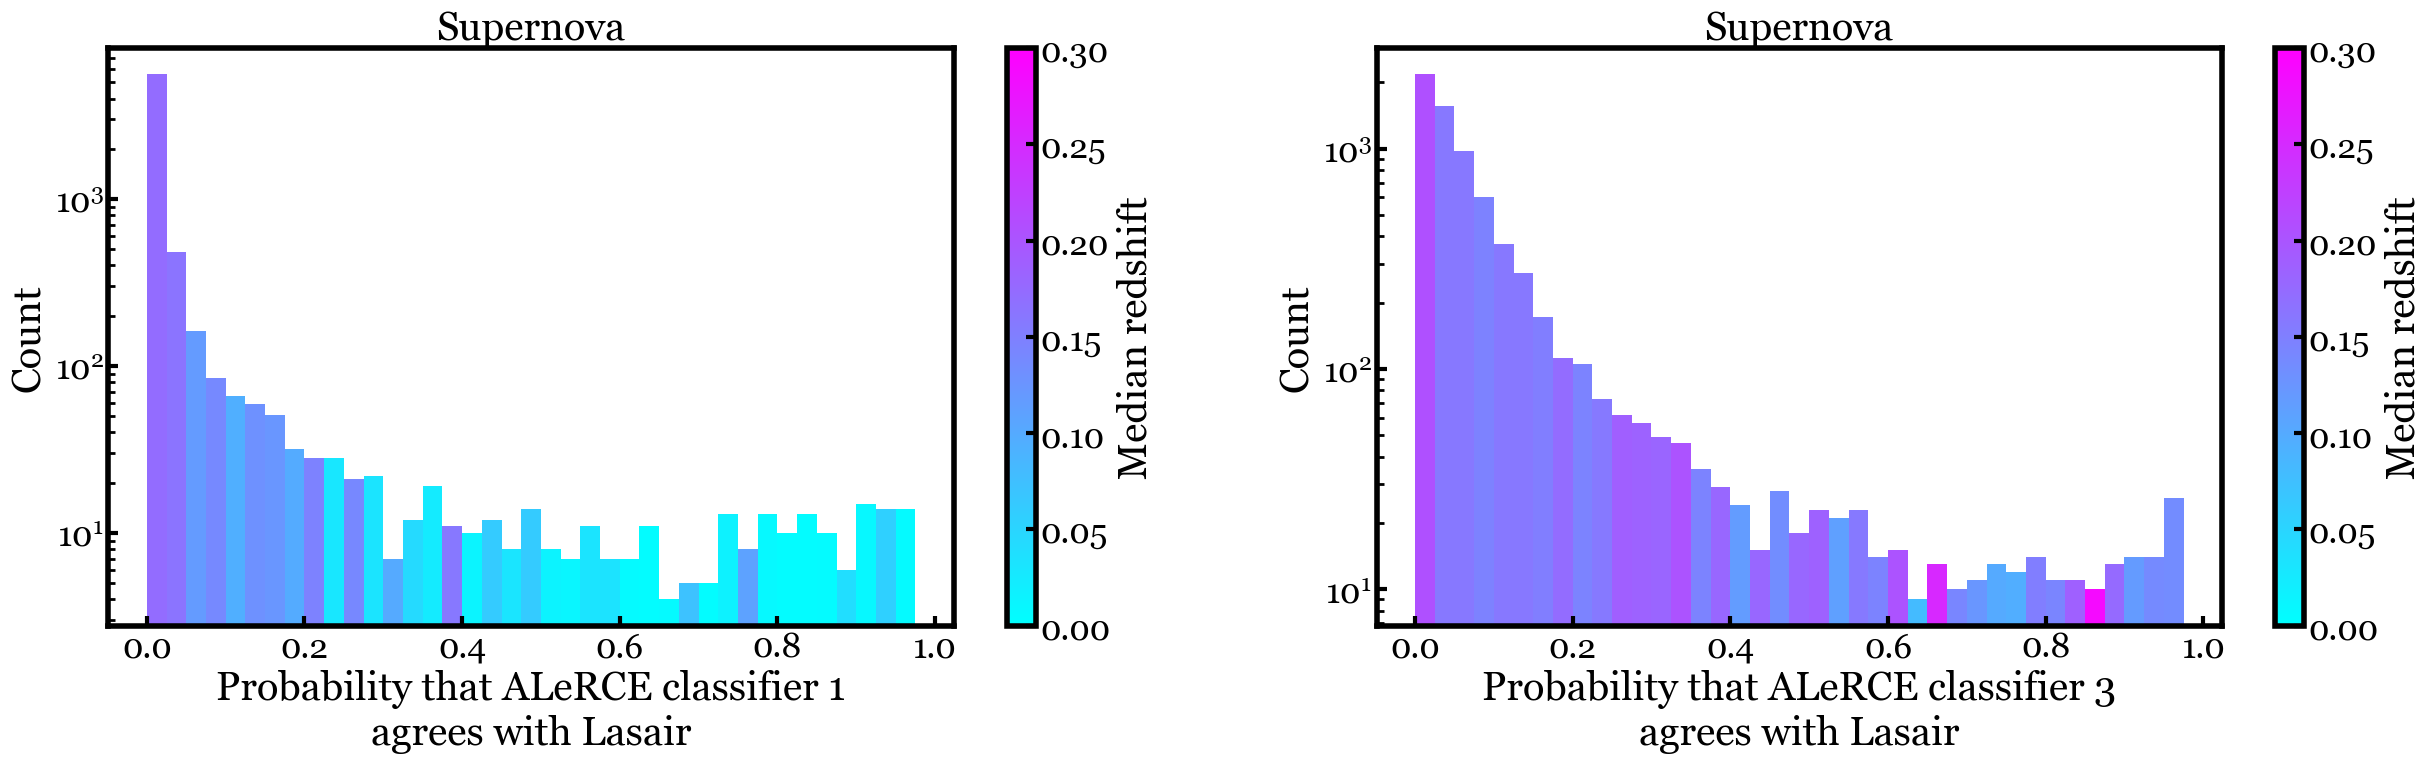

In [324]:
fig, axs = plt.subplots(1, 2, figsize = (30, 7.5))

bool_lasair_sn_good = (all_hosted["classification"] == "SN") & (all_hosted["nDiaSources"] > 10) & (all_hosted["z_best"] > 0)
bins = np.arange(0, 1, 0.025)

histColoredByValue(all_hosted[bool_lasair_sn_good]["clf1_SN"], all_hosted[bool_lasair_sn_good]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[0], cmap = "cool", vmin = 0, vmax = .3)

histColoredByValue(all_hosted[bool_lasair_sn_good]["clf3_SN"], all_hosted[bool_lasair_sn_good]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[1], cmap = "cool", vmin = 0, vmax = .3)

axs[0].set(
            # ylim = (0, 1800),
            yscale = "log",
            xlabel = "Probability that ALeRCE classifier 1\nagrees with Lasair", ylabel = "Count",
            title = "Supernova",)
axs[1].set(
            # ylim = (0, 1800),
            yscale = "log",
            xlabel = "Probability that ALeRCE classifier 3\nagrees with Lasair", ylabel = "Count",
            title = "Supernova",)

Text(0.5, -0.1, 'Probabilities given by ALeRCE classifier 10')

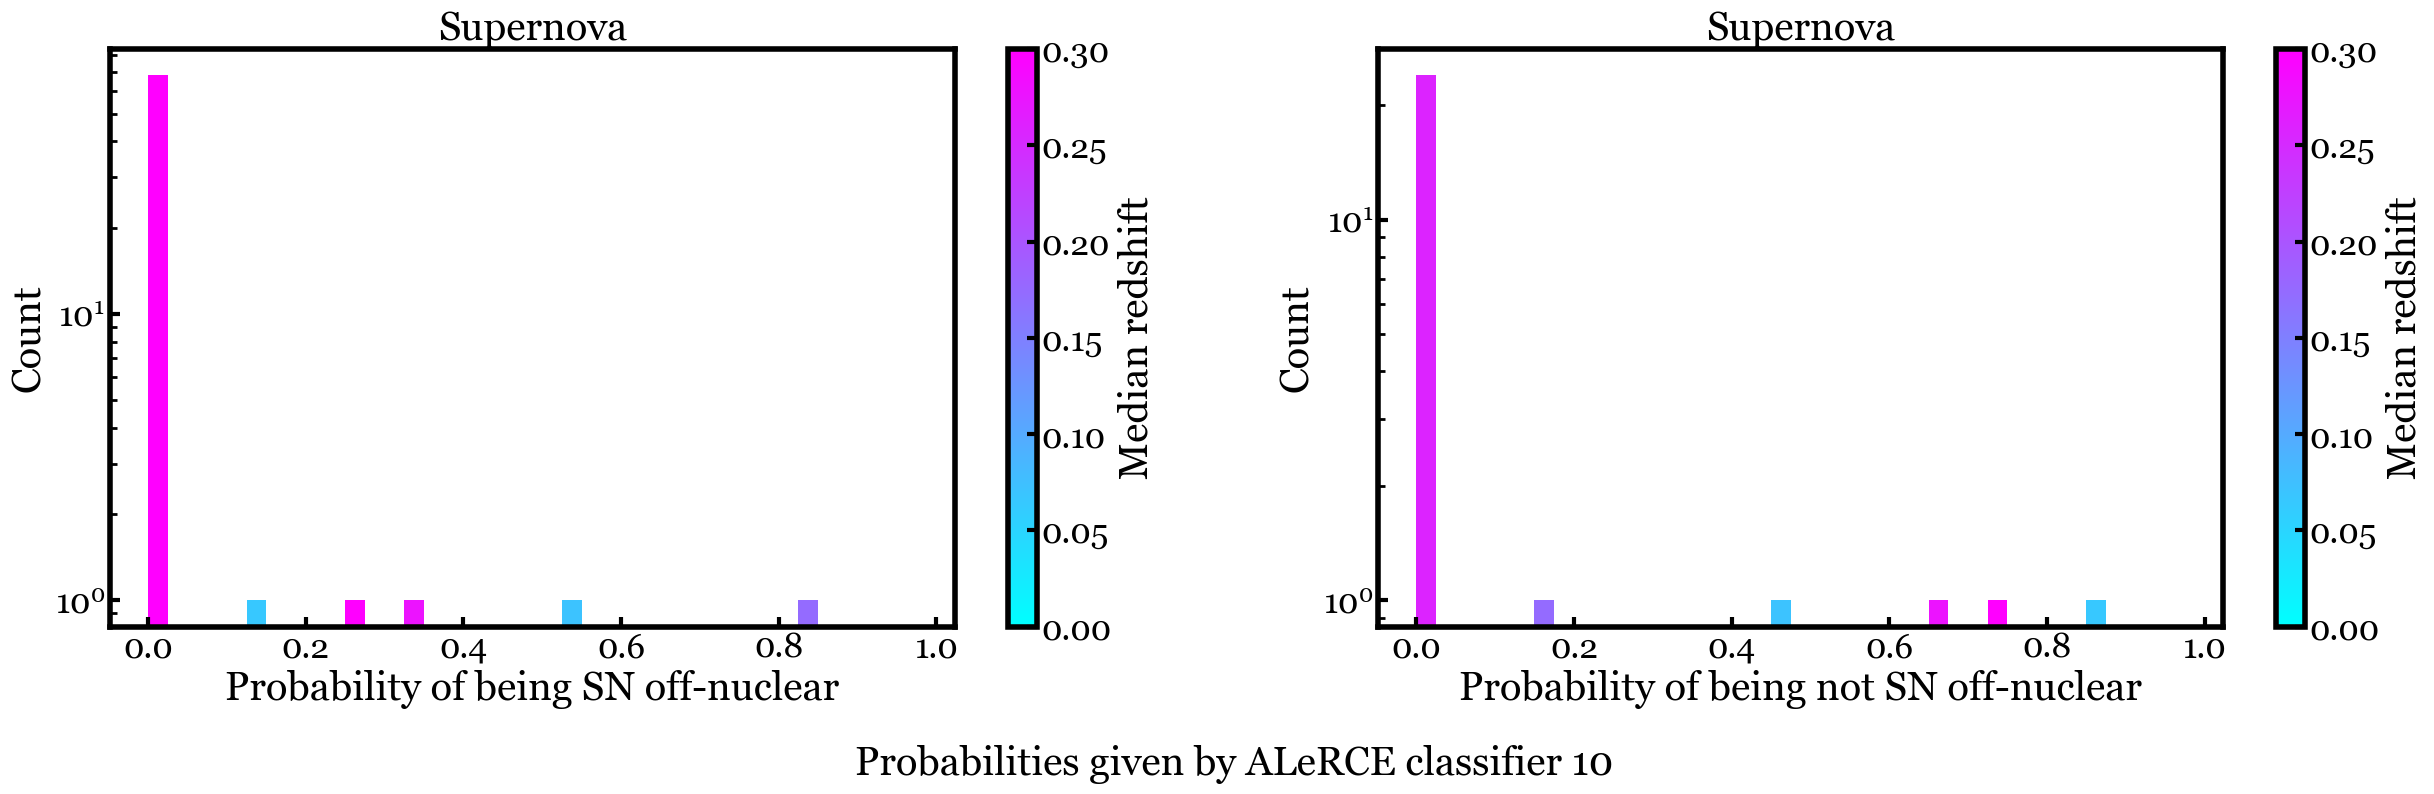

In [329]:
fig, axs = plt.subplots(1, 2, figsize = (30, 7.5))

bool_lasair_sn_good = (all_hosted["classification"] == "SN") & (all_hosted["nDiaSources"] > 10) & (all_hosted["z_best"] > 0)
bins = np.arange(0, 1, 0.025)

histColoredByValue(all_hosted[bool_lasair_sn_good]["clf10_SNoffnuclear"], all_hosted[bool_lasair_sn_good]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[0], cmap = "cool", vmin = 0, vmax = .3)

histColoredByValue(all_hosted[bool_lasair_sn_good]["clf10_notSNoffnuclear"], all_hosted[bool_lasair_sn_good]["z_best"],
                   bins = bins, label = "Median redshift", ax = axs[1], cmap = "cool", vmin = 0, vmax = .3)

axs[0].set(
            # ylim = (0, 1800),
            yscale = "log",
            xlabel = "Probability of being SN off-nuclear", ylabel = "Count",
            title = "Supernova",)
axs[1].set(
            # ylim = (0, 1800),
            yscale = "log",
            xlabel = "Probability of being not SN off-nuclear", ylabel = "Count",
            title = "Supernova",)

fig.supxlabel("Probabilities given by ALeRCE classifier 10", y = -0.1)

### Where classifier 1 disagrees with Lasair, what is the distribution of classifications that ALeRCE makes?

Text(0.5, -0.1, 'Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being an AGN')

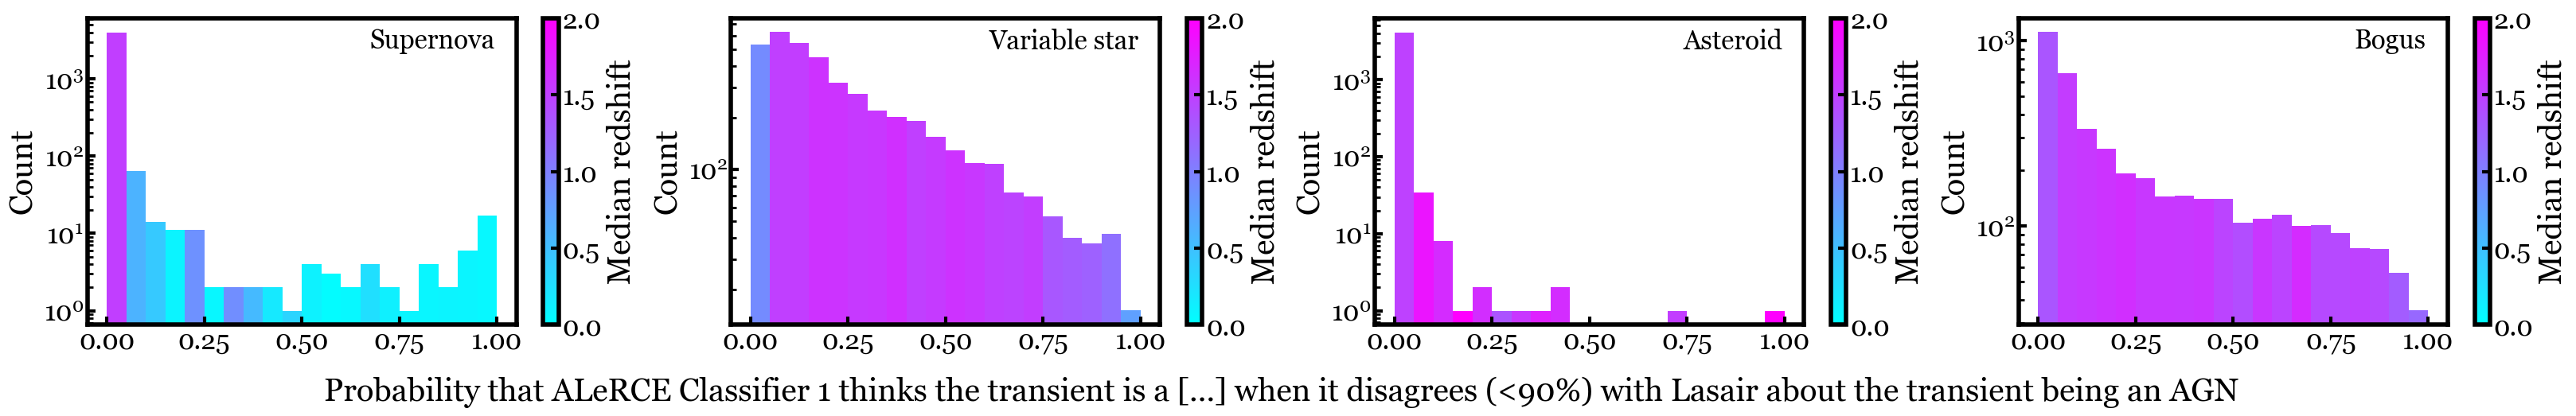

In [334]:
fig, axs = plt.subplots(1, 4, figsize = (40, 5))

disagreement_AGN_clf1 = (all_hosted["classification"] == "AGN") & (all_hosted["clf1_AGN"] < .9) & (all_hosted["nDiaSources"] > 5)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2, 3], ["SN", "VS", "asteroid", "bogus"], ["Supernova", "Variable star", "Asteroid", "Bogus"]):
    histColoredByValue(all_hosted[disagreement_AGN_clf1][f"clf1_{type}"], all_hosted[disagreement_AGN_clf1]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = 2)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being an AGN", y = -.1)

Text(0.5, -0.1, 'Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being an AGN')

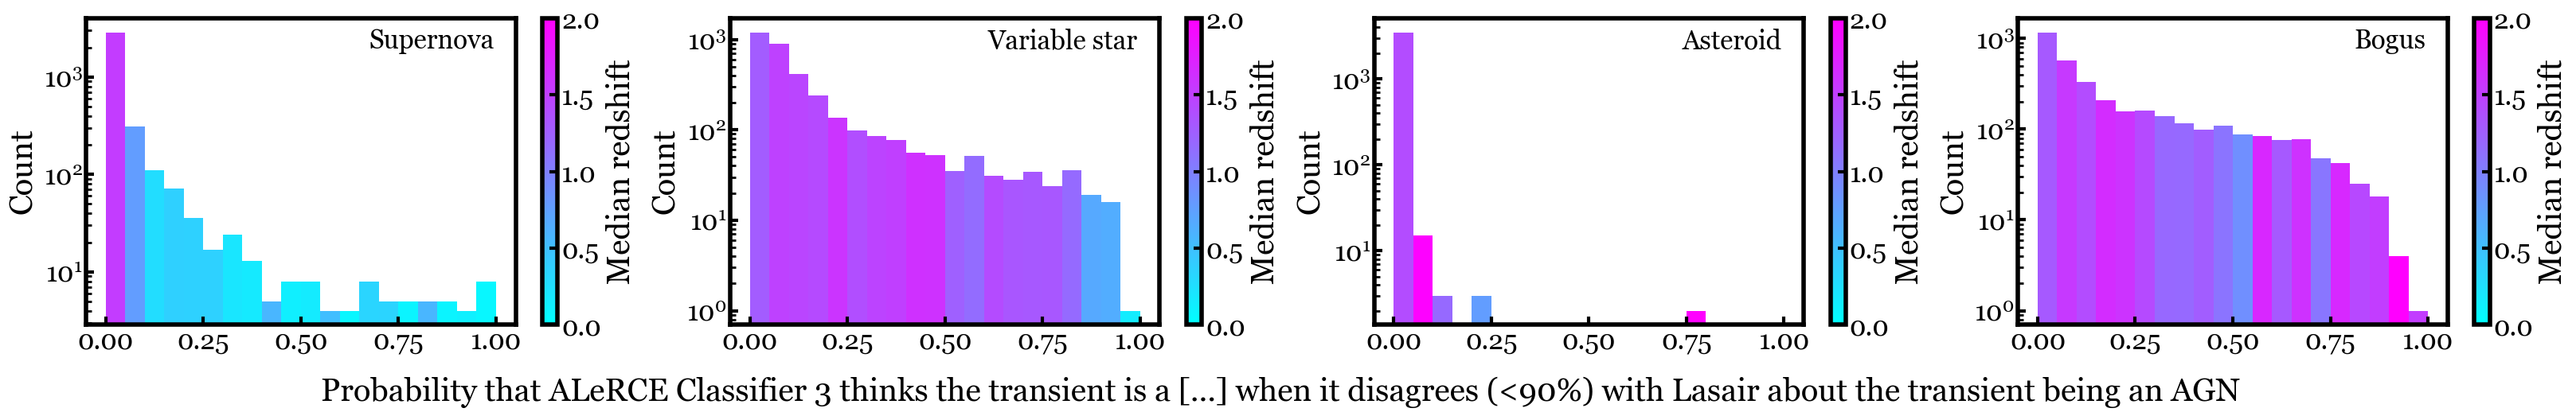

In [335]:
fig, axs = plt.subplots(1, 4, figsize = (40, 5))

disagreement_AGN_clf3 = (all_hosted["classification"] == "AGN") & (all_hosted["clf3_AGN"] < .9) & (all_hosted["nDiaSources"] > 5)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2, 3], ["SN", "VS", "asteroid", "bogus"], ["Supernova", "Variable star", "Asteroid", "Bogus"]):
    histColoredByValue(all_hosted[disagreement_AGN_clf3][f"clf3_{type}"], all_hosted[disagreement_AGN_clf3]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = 2)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being an AGN", y = -.1)

Text(0.5, -0.1, 'Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova')

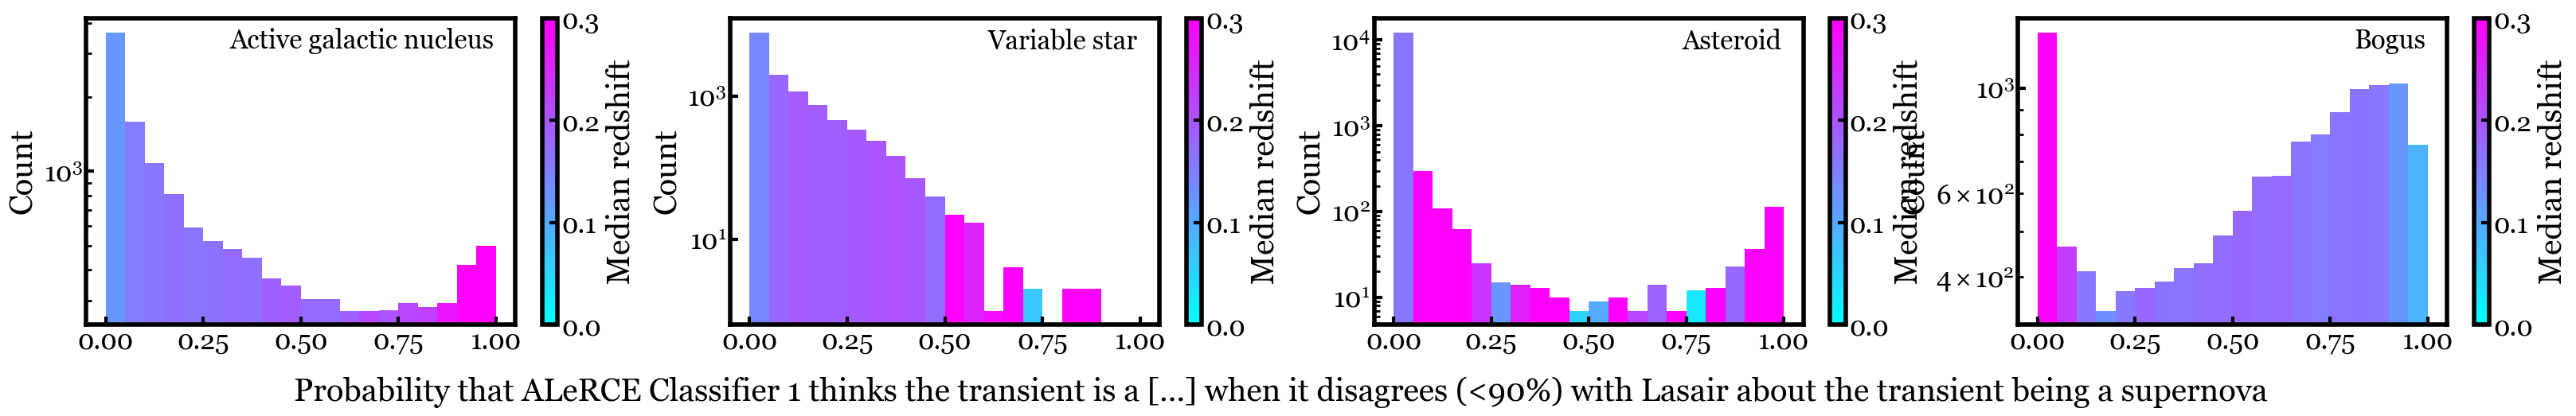

In [337]:
fig, axs = plt.subplots(1, 4, figsize = (40, 5))

disagreement_SN_clf1 = (all_hosted["classification"] == "SN") & (all_hosted["clf1_SN"] < .9) & (all_hosted["nDiaSources"] > 5)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2, 3], ["AGN", "VS", "asteroid", "bogus"], ["Active galactic nucleus", "Variable star", "Asteroid", "Bogus"]):
    histColoredByValue(all_hosted[disagreement_SN_clf1][f"clf1_{type}"], all_hosted[disagreement_SN_clf1]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = .3)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova", y = -.1)

Text(0.5, -0.1, 'Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova')

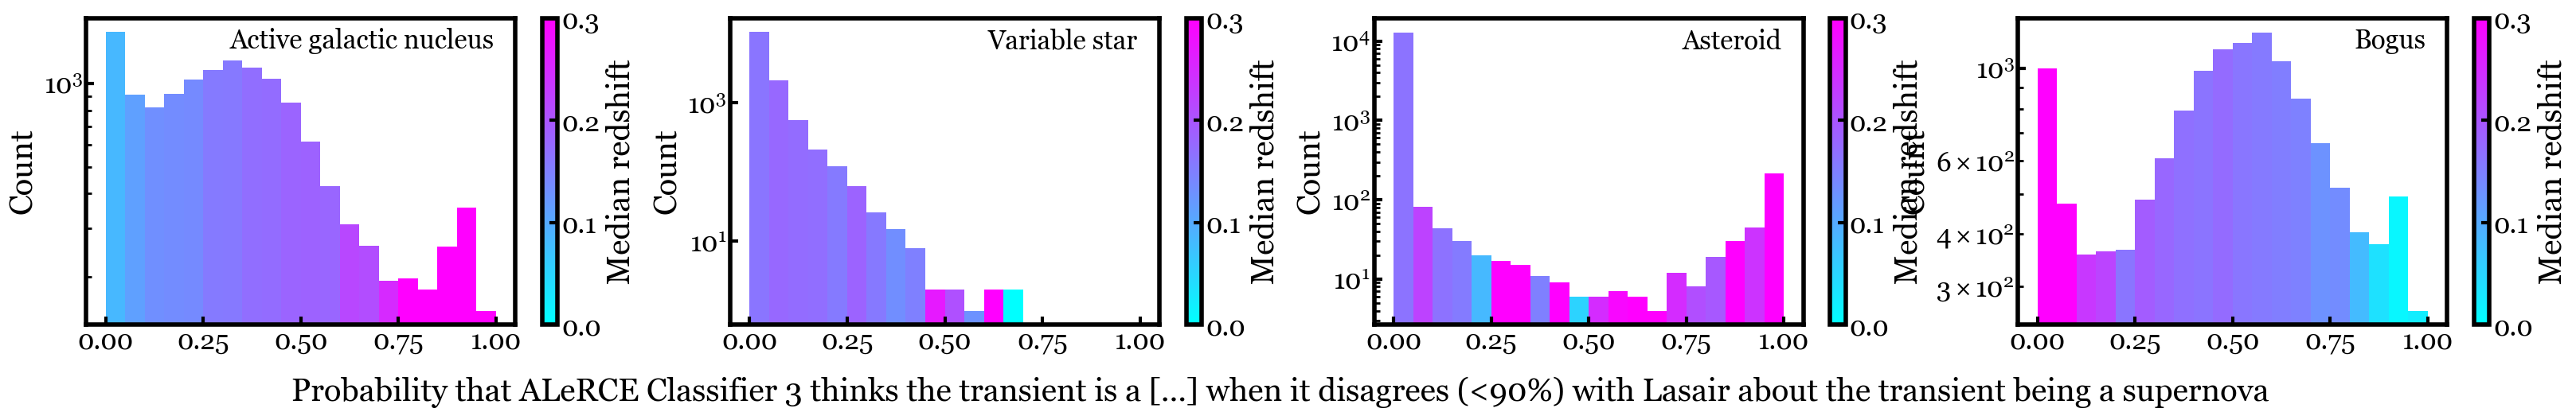

In [338]:
fig, axs = plt.subplots(1, 4, figsize = (40, 5))

disagreement_SN_clf3 = (all_hosted["classification"] == "SN") & (all_hosted["clf3_SN"] < .9) & (all_hosted["nDiaSources"] > 5)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2, 3], ["AGN", "VS", "asteroid", "bogus"], ["Active galactic nucleus", "Variable star", "Asteroid", "Bogus"]):
    histColoredByValue(all_hosted[disagreement_SN_clf3][f"clf3_{type}"], all_hosted[disagreement_SN_clf3]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = .3)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova", y = -.1)

Text(0.5, -0.2, 'Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova,\nbut ALeRCE does not think the event is bogus (<10% bogus)')

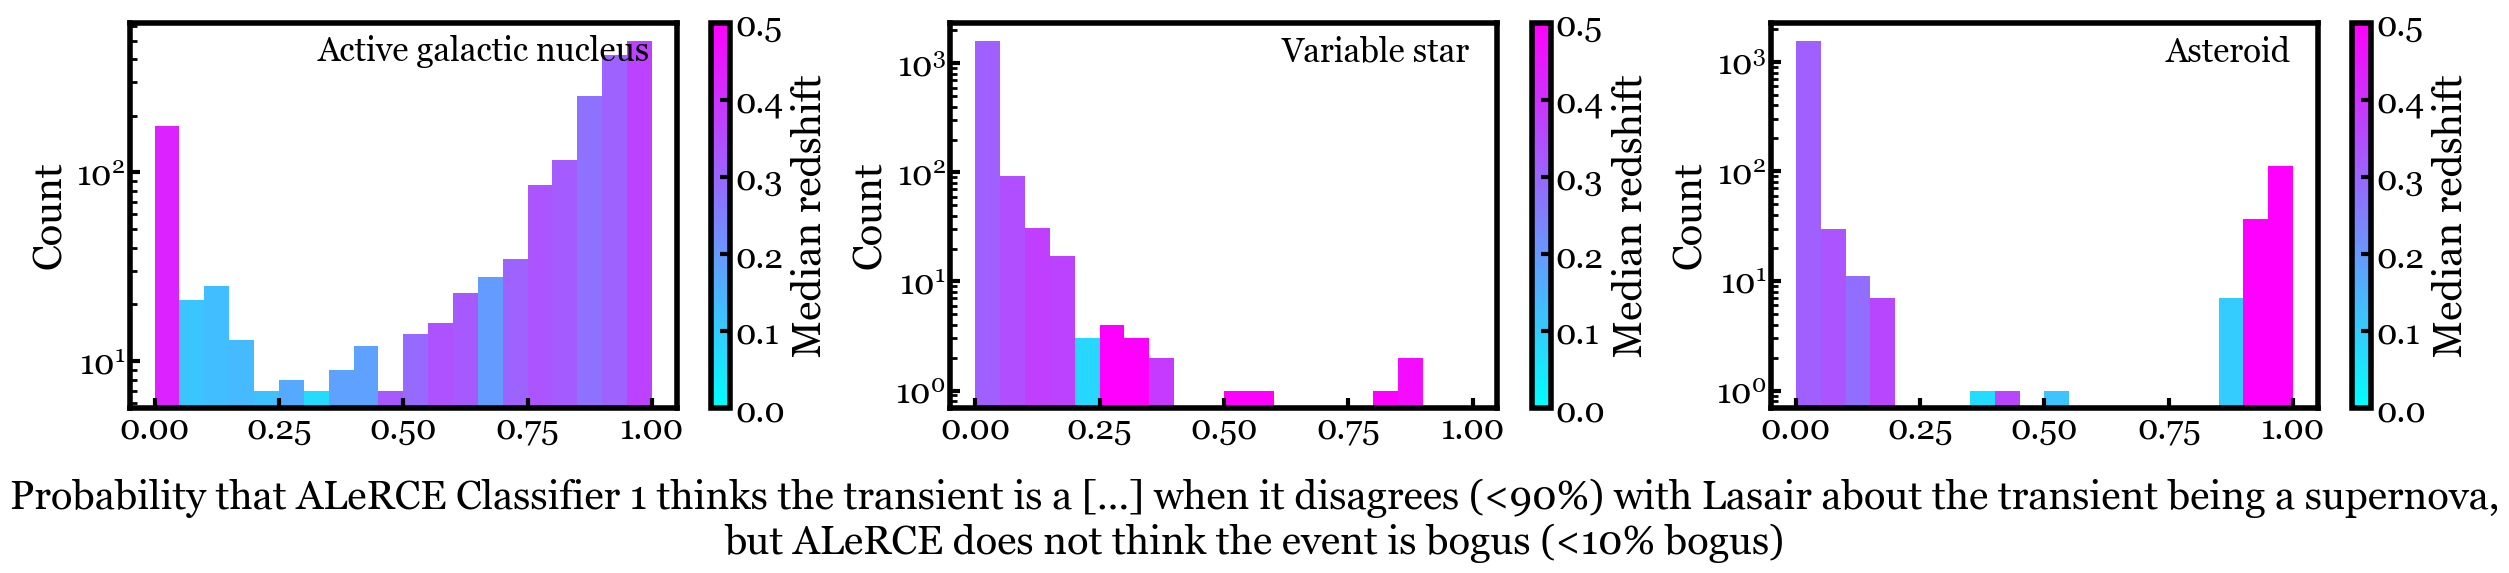

In [341]:
fig, axs = plt.subplots(1, 3, figsize = (30, 5))

disagreement_SN_clf1 = (all_hosted["classification"] == "SN") & (all_hosted["clf1_SN"] < .9) & (all_hosted["nDiaSources"] > 5) & (all_hosted["clf1_bogus"] < .1)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2], ["AGN", "VS", "asteroid"], ["Active galactic nucleus", "Variable star", "Asteroid"]):
    histColoredByValue(all_hosted[disagreement_SN_clf1][f"clf1_{type}"], all_hosted[disagreement_SN_clf1]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = .5)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 1 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova,\nbut ALeRCE does not think the event is bogus (<10% bogus)", y = -.2)

Text(0.5, -0.25, 'Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova,\nbut ALeRCE does not think the event is bogus (<10% bogus)')

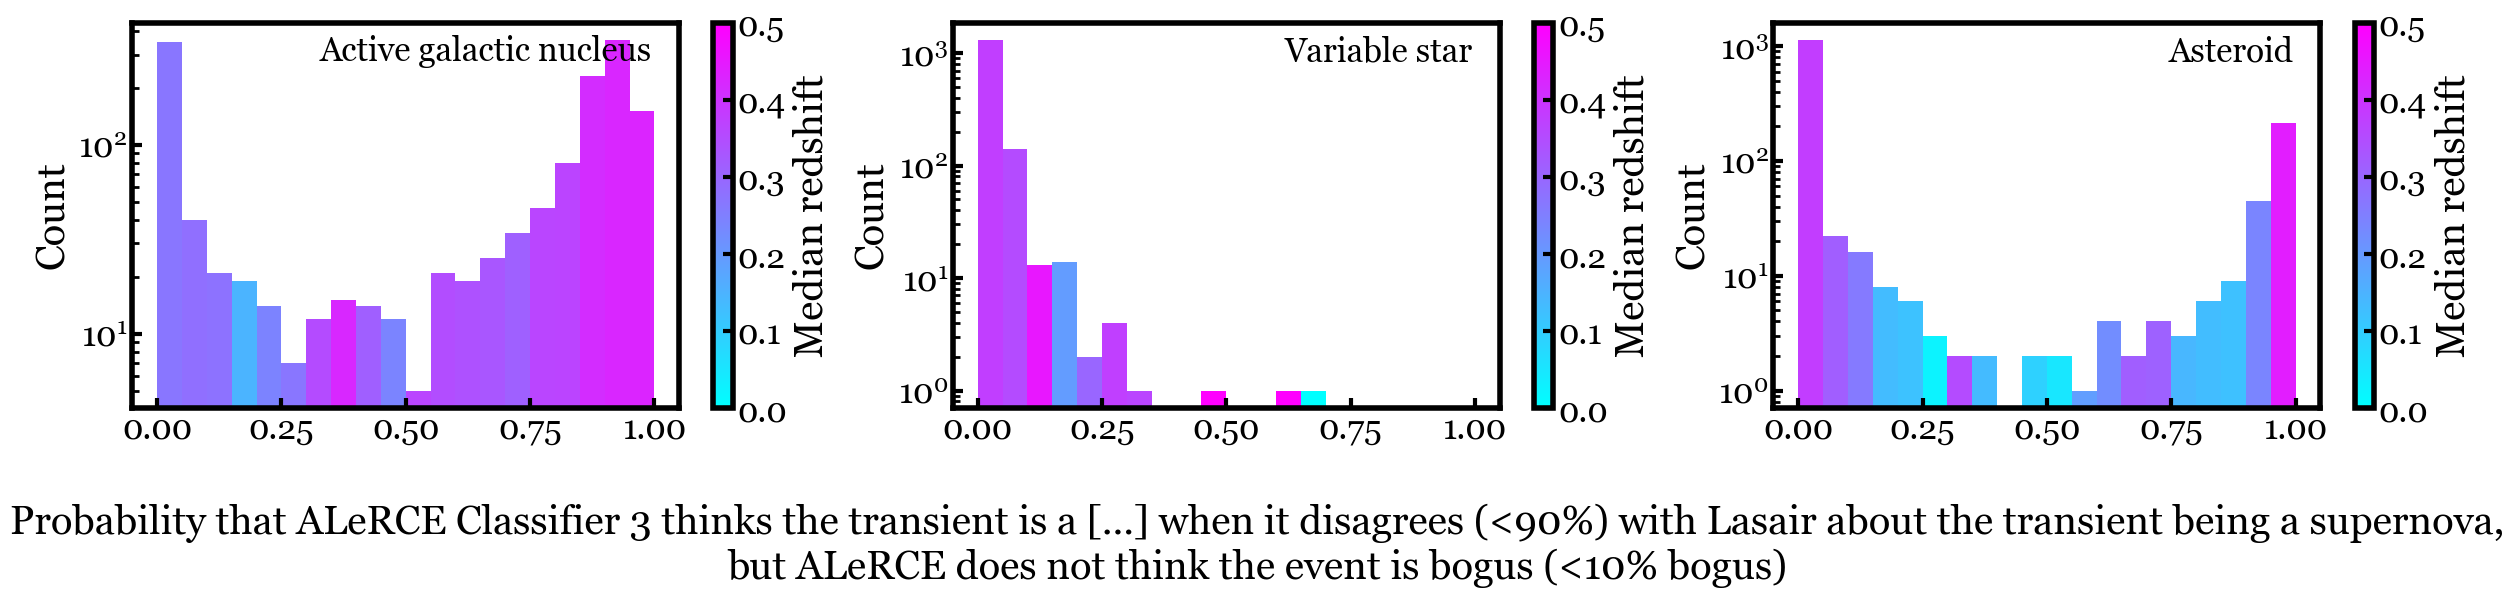

In [342]:
fig, axs = plt.subplots(1, 3, figsize = (30, 5))

disagreement_SN_clf3 = (all_hosted["classification"] == "SN") & (all_hosted["clf3_SN"] < .9) & (all_hosted["nDiaSources"] > 5) & (all_hosted["clf3_bogus"] < .1)

bins = np.arange(0, 1.025, 0.05)

for idx, type, name in zip([0, 1, 2], ["AGN", "VS", "asteroid"], ["Active galactic nucleus", "Variable star", "Asteroid"]):
    histColoredByValue(all_hosted[disagreement_SN_clf3][f"clf3_{type}"], all_hosted[disagreement_SN_clf3]["z_best"],
                       bins = bins, label = "Median redshift", ax = axs[idx], vmin = 0, vmax = .5)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")

for ax in axs: ax.set(yscale = "log", ylabel = "Count")

fig.supxlabel("Probability that ALeRCE Classifier 3 thinks the transient is a [...] when it disagrees (<90%) with Lasair about the transient being a supernova,\nbut ALeRCE does not think the event is bogus (<10% bogus)", y = -.25)

Text(0.125, 1.05, 'Transients where both ALeRCE classifiers 1 and 3 agree on classification\n($(p_1 - 1)^2 + (p_3 - 1)^2 < 0.1^2$)')

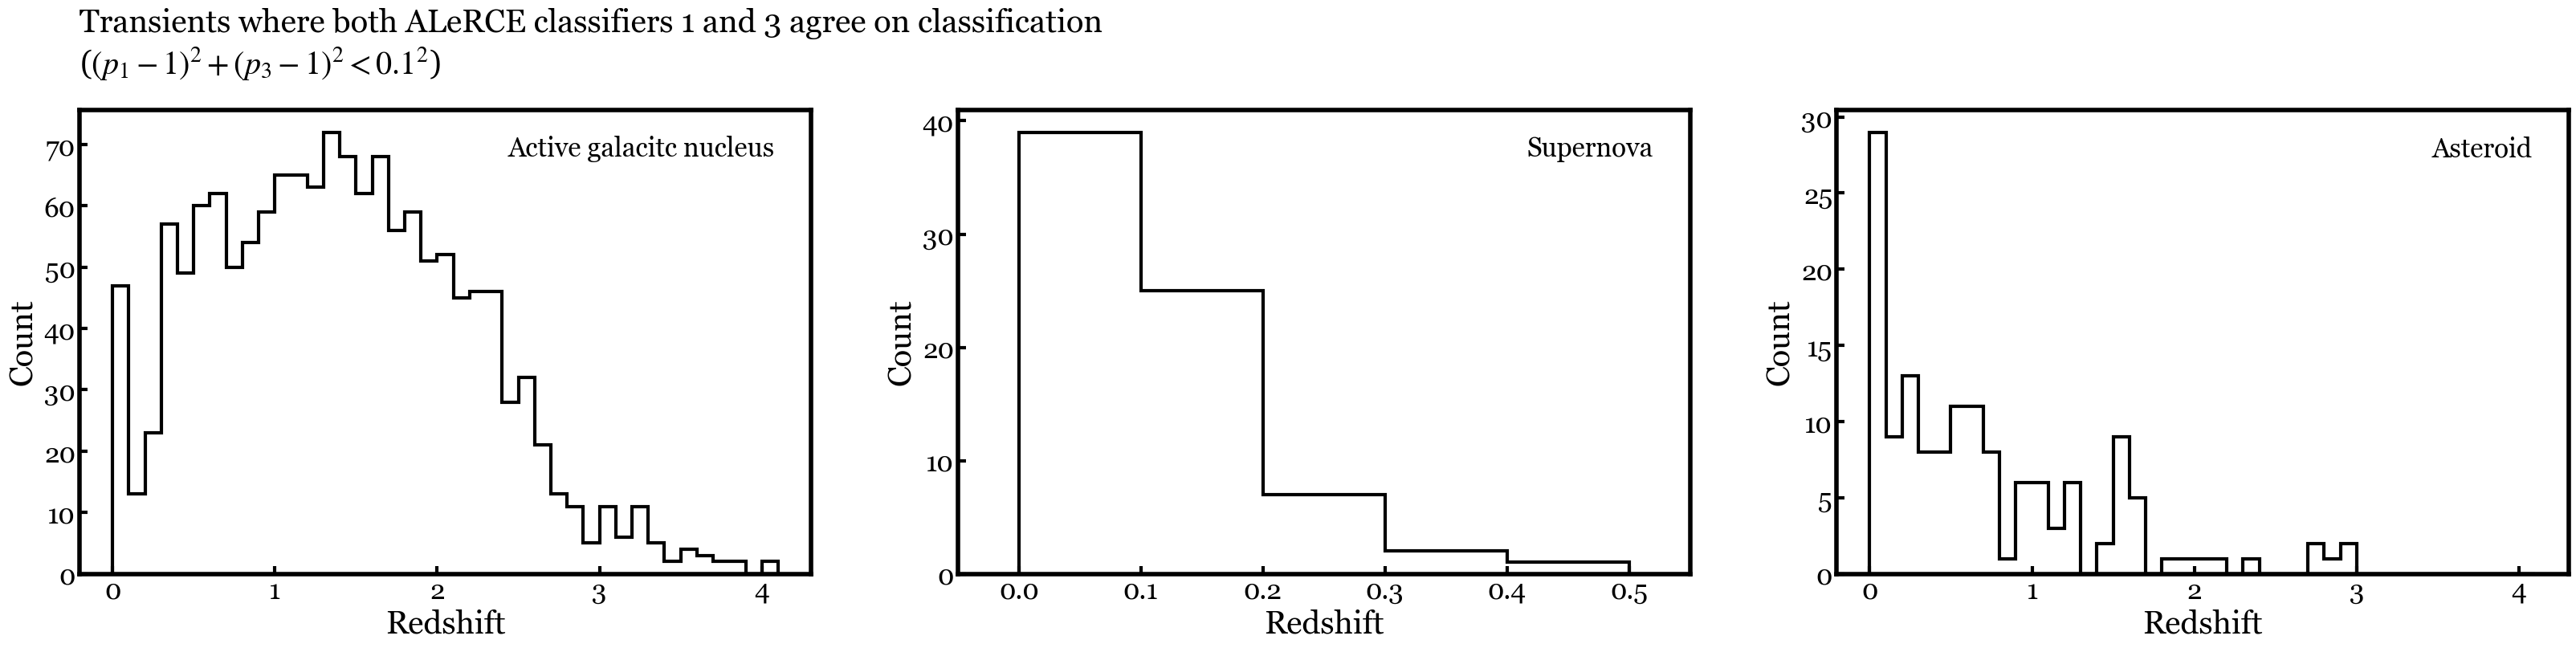

In [356]:
fig, axs = plt.subplots(1, 3, figsize = (40, 7.5))

bins = np.arange(0, 4.2, 0.1)

for idx, type, name in zip([0, 1, 2], ["AGN", "SN", "asteroid"], ["Active galacitc nucleus", "Supernova", "Asteroid"]): 

    confirmed = (all_hosted["nDiaSources"] > 5) &\
                    (((all_hosted[f"clf1_{type}"] - 1)**2 + (all_hosted[f"clf3_{type}"] - 1)**2) < 0.1**2) #& (all_hosted[f"clf3_{type}"] > 0.9)
    axs[idx].hist(all_hosted[confirmed]["z_best"], bins = bins, histtype = "step", color = "black", linewidth = 3)
    axs[idx].text(0.95, 0.9, name, transform = axs[idx].transAxes, horizontalalignment = "right")
    axs[idx].set(xlabel = "Redshift", ylabel = "Count")

axs[1].set(xlim = (-0.05, 0.55))

fig.suptitle("Transients where both ALeRCE classifiers 1 and 3 agree on classification\n($(p_1 - 1)^2 + (p_3 - 1)^2 < 0.1^2$)",
             x = .125, y = 1.05,
             horizontalalignment = "left", multialignment = "left")

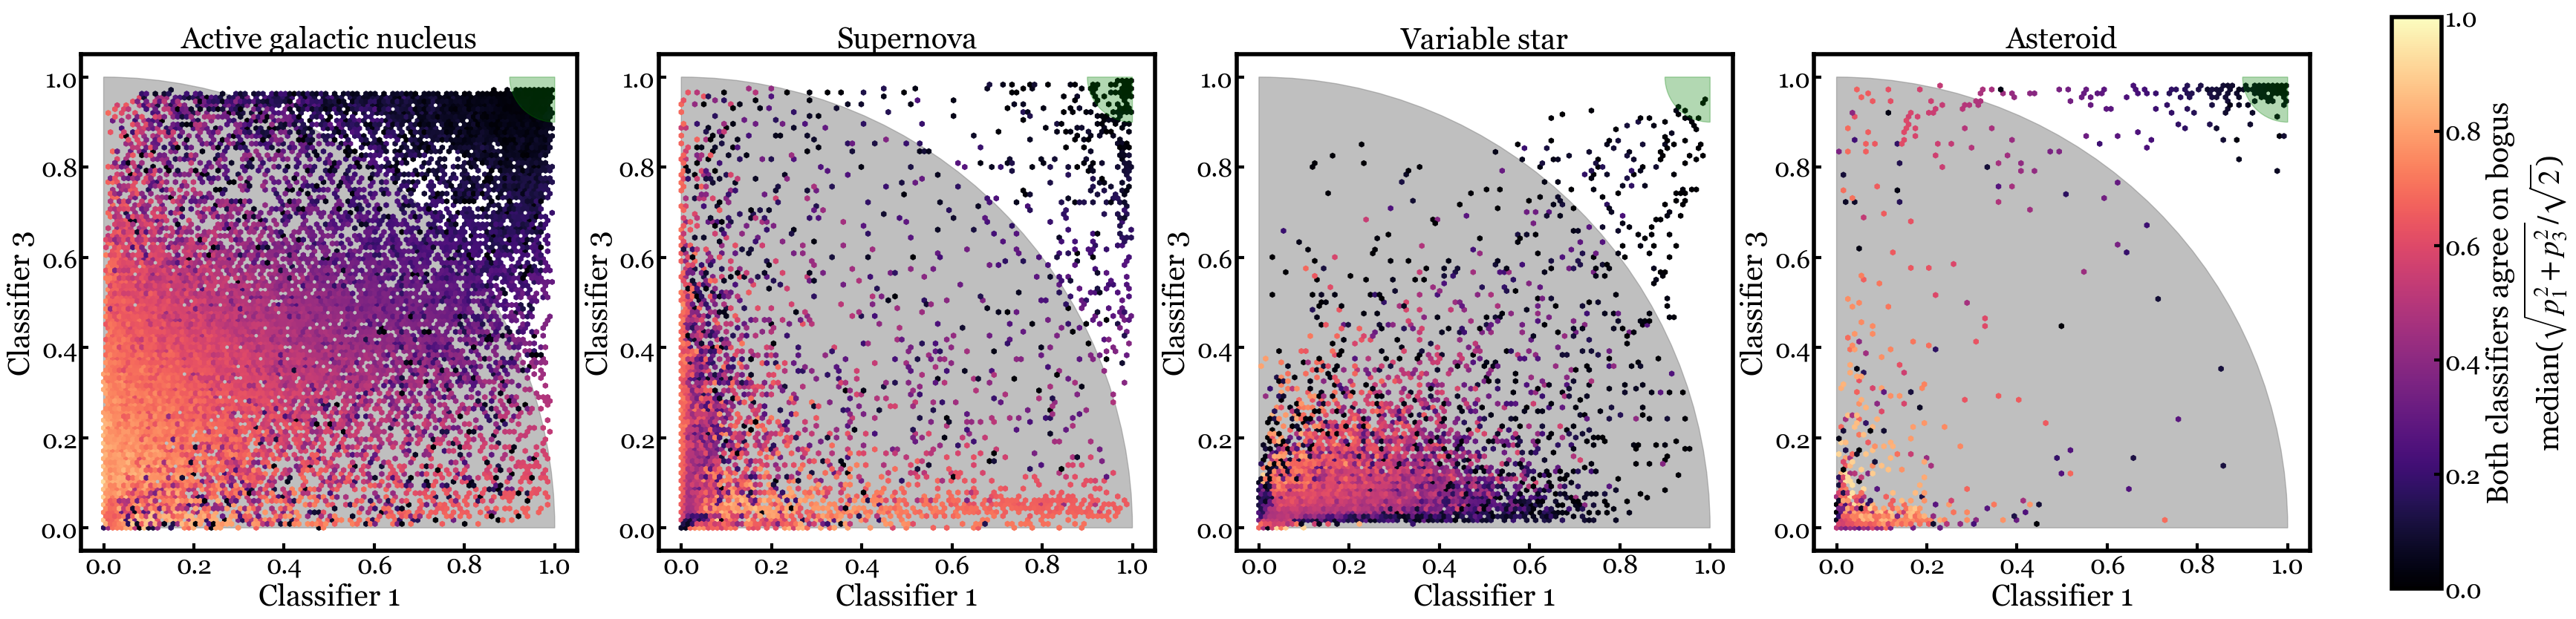

In [355]:
### Consider the rate at which the two classifiers agree, and plot out the redshift distributions for both

fig, axs = plt.subplots(1, 5, figsize = (41, 10), width_ratios = [10, 10, 10, 10, 1])
bool_good = all_hosted["nDiaSources"] > 5

for idx, type, name in zip([0, 1, 2, 3],
                           ["AGN", "SN", "VS", "asteroid"],
                           ["Active galactic nucleus", "Supernova", "Variable star", "Asteroid"]):
    
    ax = axs[idx]
    ax.add_patch(Wedge((0, 0), 1, 0, 90, alpha=.5, color="gray")) 

    mappable = ax.hexbin(all_hosted[bool_good][f"clf1_{type}"], all_hosted[bool_good][f"clf3_{type}"],
                            mincnt = 0, vmin = 0, vmax = 1,
                            C = np.sqrt(all_hosted[bool_good][f"clf1_bogus"] ** 2 + all_hosted[bool_good][f"clf3_bogus"]**2)/np.sqrt(2),
                            reduce_C_function = np.median)

    ax.add_patch(Wedge((1, 1), 0.1, 180, 270, alpha=.3, color="green"))  
    ax.set_aspect("equal")
    
    ax.set(xlabel = "Classifier 1", ylabel = "Classifier 3", title = name)

fig.colorbar(mappable = mappable, cax = axs[4], label = "Both classifiers agree on bogus\nmedian($\sqrt{p_1^2 + p_3^2}/\sqrt{2}$)")

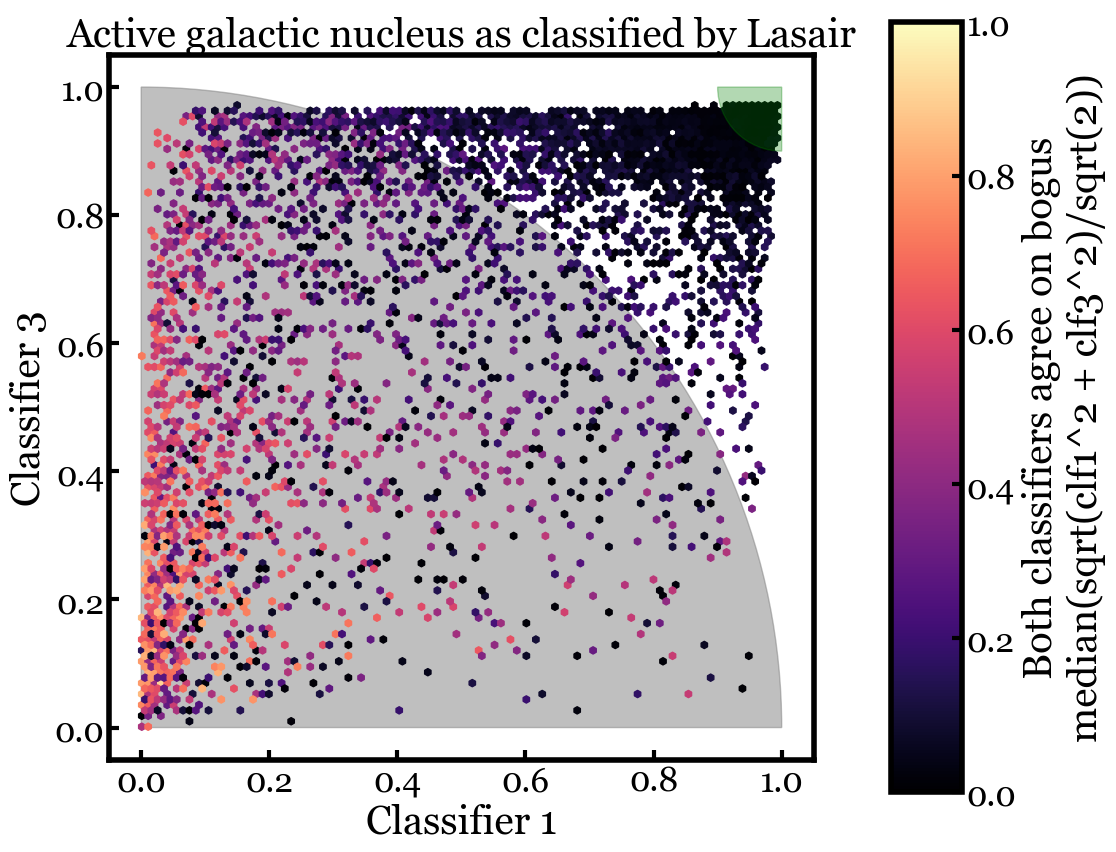

In [228]:
### Consider the rate at which the two classifiers agree, and plot out the redshift distributions for both

fig, axs = plt.subplots(1, 2, figsize = (11, 10), width_ratios = [10, 1])
bool_good = (all_hosted["nDiaSources"] > 5) & (all_hosted["classification"] == "AGN")

for idx, type, name in zip([0],
                           ["AGN"],
                           ["Active galactic nucleus as classified by Lasair"]):
    
    ax = axs[idx]
    ax.add_patch(Wedge((0, 0), 1, 0, 90, alpha=.5, color="gray")) 

    mappable = ax.hexbin(all_hosted[bool_good][f"clf1_{type}"], all_hosted[bool_good][f"clf3_{type}"],
                            mincnt = 0, vmin = 0, vmax = 1,
                            C = np.sqrt(all_hosted[bool_good][f"clf1_bogus"] ** 2 + all_hosted[bool_good][f"clf3_bogus"]**2)/np.sqrt(2),
                            reduce_C_function = np.median)

    ax.add_patch(Wedge((1, 1), 0.1, 180, 270, alpha=.3, color="green"))  
    ax.set_aspect("equal")
    
    ax.set(xlabel = "Classifier 1", ylabel = "Classifier 3", title = name)

fig.colorbar(mappable = mappable, cax = axs[1], label = "Both classifiers agree on bogus\nmedian(sqrt(clf1^2 + clf3^2)/sqrt(2))")